In [1]:
from copy import deepcopy

import numpy as np
import pandas as pd
from scipy import stats

from sklearn.metrics import mean_absolute_percentage_error

import dowhy
from dowhy import CausalModel

from sklearn.linear_model import LinearRegression, LogisticRegression, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from lightgbm import LGBMRegressor, LGBMClassifier

import networkx as nx

from tqdm import tqdm

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

import graphviz

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Defining binary treatment and outcome variable:
dataset["D"] = (dataset["treatment"] != 0).astype(int)
dataset["Y"] = dataset["voted"]

In [2]:
from toolz import curry

@curry
def elast(data, y, t):
    return (np.sum((data[t] - data[t].mean())*(data[y] - data[y].mean())) /
            np.sum((data[t] - data[t].mean())**2))

def cumulative_gain(dataset, prediction, y, t, min_periods=30, steps=100):
    size = len(dataset)
    order = np.argsort(-dataset[prediction].to_numpy(), kind="stable")
    yv = dataset[y].to_numpy(float)[order]
    tv = dataset[t].to_numpy(float)[order]

    k = np.arange(1, size + 1)
    St, Sy = np.cumsum(tv), np.cumsum(yv)
    Sty, Stt = np.cumsum(tv * yv), np.cumsum(tv * tv)

    # Same slope as elast() on the top-k rows, for every k at once
    num = Sty - St * Sy / k
    den = Stt - St**2 / k

    n_rows = np.array(list(range(min_periods, size, size // steps)) + [size])
    return num[n_rows - 1] / den[n_rows - 1] * (n_rows / size)

In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
#from nb21 import cumulative_gain, elast

In [4]:
y = "Y"
T = "D"
X = ["sex", "yob", "g2000", "g2002", "p2000", "p2002", "p2004", "hh_size"]

In [5]:
from lightgbm import LGBMRegressor

np.random.seed(123)
s_learner = LGBMRegressor(max_depth=3, min_child_samples=30)
s_learner.fit(dataset[X+[T]], dataset[y]);

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023611 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 108
[LightGBM] [Info] Number of data points in the train set: 344084, number of used features: 9
[LightGBM] [Info] Start training from score 0.315900
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMRegressor

train, test = train_test_split(dataset, test_size=0.3, random_state=123)

def plot_gain(cate_train, cate_test, title):
    gain_test  = cumulative_gain(test.assign(cate=cate_test),   "cate", y=y, t=T)
    gain_train = cumulative_gain(train.assign(cate=cate_train), "cate", y=y, t=T)
    plt.plot(gain_test,  color="C0", label="Test")
    plt.plot(gain_train, color="C1", label="Train")
    plt.plot([0, 100], [0, elast(test, y, T)], linestyle="--", color="black", label="Baseline")
    plt.legend(); plt.title(title); plt.show()

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016925 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 108
[LightGBM] [Info] Number of data points in the train set: 240858, number of used features: 9
[LightGBM] [Info] Start training from score 0.316103
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

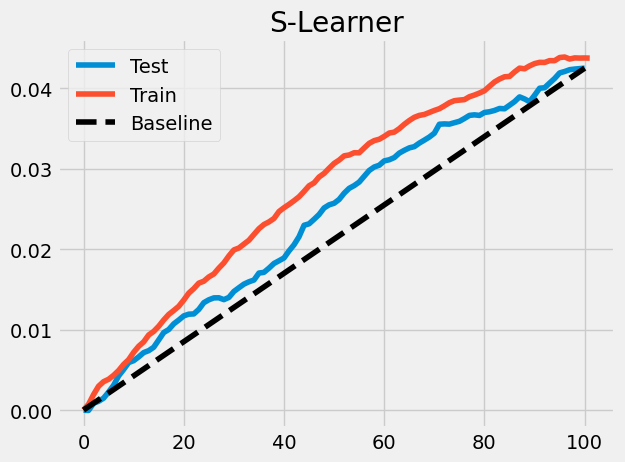

In [10]:
# Running the S-Learner:

np.random.seed(123)
s_learner = LGBMRegressor(max_depth=3, min_child_samples=30)
s_learner.fit(train[X + [T]], train[y])

s_cate_train = s_learner.predict(train[X].assign(**{T: 1})) - s_learner.predict(train[X].assign(**{T: 0}))
s_cate_test  = s_learner.predict(test[X].assign(**{T: 1}))  - s_learner.predict(test[X].assign(**{T: 0}))
plot_gain(s_cate_train, s_cate_test, "S-Learner")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007228 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 104
[LightGBM] [Info] Number of data points in the train set: 134001, number of used features: 8
[LightGBM] [Info] Start training from score 0.296699
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

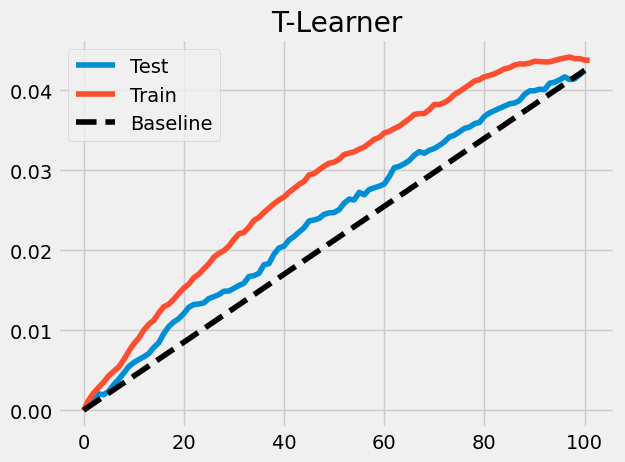

In [11]:
# Running the T-Learner:

np.random.seed(123)
m0 = LGBMRegressor(max_depth=2, min_child_samples=60)
m1 = LGBMRegressor(max_depth=2, min_child_samples=60)
m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])

t_cate_train = m1.predict(train[X]) - m0.predict(train[X])
t_cate_test  = m1.predict(test[X])  - m0.predict(test[X])
plot_gain(t_cate_train, t_cate_test, "T-Learner")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013720 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 104
[LightGBM] [Info] Number of data points in the train set: 134001, number of used features: 8
[LightGBM] [Info] Start training from score 0.296699
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

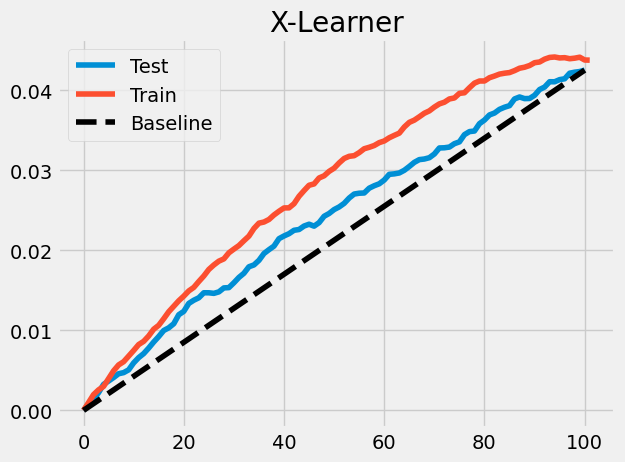

In [12]:
# Running the X-Learner:

np.random.seed(123)
m0 = LGBMRegressor(max_depth=2, min_child_samples=30)
m1 = LGBMRegressor(max_depth=2, min_child_samples=30)
g  = LogisticRegression(penalty=None, max_iter=1000)

m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])
g.fit(train[X], train[T])

# The imputed treatment effects:
d_train = np.where(train[T] == 0,
                   m1.predict(train[X]) - train[y],
                   train[y] - m0.predict(train[X]))

mx0 = LGBMRegressor(max_depth=2, min_child_samples=30)
mx1 = LGBMRegressor(max_depth=2, min_child_samples=30)
mx0.fit(train.query(f"{T}==0")[X], d_train[train[T] == 0])
mx1.fit(train.query(f"{T}==1")[X], d_train[train[T] == 1])

def x_cate(df):
    e = g.predict_proba(df[X])[:, 1]
    return e * mx0.predict(df[X]) + (1 - e) * mx1.predict(df[X])

plot_gain(x_cate(train), x_cate(test), "X-Learner")

In [13]:
import statsmodels.formula.api as smf

df = dataset.copy()

# Benchmark: difference in means = OLS of Y on D.
# Gerber et al. randomized by household, so cluster SEs on household id
# (check the column name: dataset.columns -> usually "hh_id").
rct = smf.ols(f"{y} ~ {T}", data=df).fit(cov_type="cluster",
                                          cov_kwds={"groups": df["hh_id"]})
tau_rct = rct.params[T]
se_rct = rct.bse[T]
print(f"tau_RCT = {tau_rct:.4f} (SE {se_rct:.4f})")

tau_RCT = 0.0434 (SE 0.0020)


In [14]:
from lightgbm import LGBMRegressor
from sklearn.linear_model import LogisticRegression

def s_learner(fit_df, pred_df, seed=123):
    m = LGBMRegressor(max_depth=3, min_child_samples=30, random_state=seed, verbose=-1)
    m.fit(fit_df[X + [T]], fit_df[y])
    return (m.predict(pred_df[X].assign(**{T: 1})) -
            m.predict(pred_df[X].assign(**{T: 0})))

def t_learner(fit_df, pred_df, seed=123):
    m0 = LGBMRegressor(max_depth=2, min_child_samples=60, random_state=seed, verbose=-1)
    m1 = LGBMRegressor(max_depth=2, min_child_samples=60, random_state=seed, verbose=-1)
    m0.fit(fit_df.query(f"{T}==0")[X], fit_df.query(f"{T}==0")[y])
    m1.fit(fit_df.query(f"{T}==1")[X], fit_df.query(f"{T}==1")[y])
    return m1.predict(pred_df[X]) - m0.predict(pred_df[X])

def x_learner(fit_df, pred_df, seed=123):
    m0 = LGBMRegressor(max_depth=2, min_child_samples=30, random_state=seed, verbose=-1)
    m1 = LGBMRegressor(max_depth=2, min_child_samples=30, random_state=seed, verbose=-1)
    g = LogisticRegression(penalty=None, max_iter=1000)
    c, t = fit_df.query(f"{T}==0"), fit_df.query(f"{T}==1")
    m0.fit(c[X], c[y]); m1.fit(t[X], t[y]); g.fit(fit_df[X], fit_df[T])

    d0 = m1.predict(c[X]) - c[y]          # imputed effect, controls
    d1 = t[y] - m0.predict(t[X])          # imputed effect, treated
    mx0 = LGBMRegressor(max_depth=2, min_child_samples=30, random_state=seed, verbose=-1).fit(c[X], d0)
    mx1 = LGBMRegressor(max_depth=2, min_child_samples=30, random_state=seed, verbose=-1).fit(t[X], d1)

    e = g.predict_proba(pred_df[X])[:, 1]
    return e * mx0.predict(pred_df[X]) + (1 - e) * mx1.predict(pred_df[X])

learners = {"S-Learner": s_learner, "T-Learner": t_learner, "X-Learner": x_learner}
for name, f in learners.items():
    df[name] = f(df, df)

In [15]:
names = list(learners)

def summarize(df):
    rows = []
    for n in names:
        c = df[n]
        rows.append({
            "Learner": n,
            "ATE (mean CATE)": c.mean(),
            "ATE - tau_RCT": c.mean() - tau_rct,
            "SD of CATE": c.std(),
            "p5": c.quantile(.05), "p50": c.median(), "p95": c.quantile(.95),
            "Share CATE < 0": (c < 0).mean(),
        })
    return pd.DataFrame(rows).set_index("Learner")

summary = summarize(df)
print(f"tau_RCT = {tau_rct:.4f}  95% CI [{tau_rct-1.96*se_rct:.4f}, {tau_rct+1.96*se_rct:.4f}]")
print(summary.round(4))

# Household-clustered bootstrap of the learner ATEs (slow: ~B x 3 model fits)
B = 50
hh = df["hh_id"].unique()
rng = np.random.default_rng(123)
groups = df.groupby("hh_id").indices
boot = {n: [] for n in names}
for b in tqdm(range(B)):
    draw = rng.choice(hh, size=len(hh), replace=True)
    idx = np.concatenate([groups[h] for h in draw])
    db = df.iloc[idx]
    for n, f in learners.items():
        boot[n].append(f(db, db, seed=b).mean())

for n in names:
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    print(f"{n}: ATE {summary.loc[n, 'ATE (mean CATE)']:.4f}  bootstrap 95% CI [{lo:.4f}, {hi:.4f}]")

tau_RCT = 0.0434  95% CI [0.0394, 0.0473]
           ATE (mean CATE)  ATE - tau_RCT  SD of CATE      p5     p50     p95  \
Learner                                                                         
S-Learner           0.0406        -0.0028      0.0144  0.0112  0.0422  0.0614   
T-Learner           0.0427        -0.0006      0.0191  0.0080  0.0445  0.0705   
X-Learner           0.0427        -0.0007      0.0150  0.0117  0.0439  0.0646   

           Share CATE < 0  
Learner                    
S-Learner          0.0112  
T-Learner          0.0230  
X-Learner          0.0097  


100%|██████████████████████████████████████████████████████████████████████████████████| 50/50 [10:59<00:00, 13.20s/it]

S-Learner: ATE 0.0406  bootstrap 95% CI [0.0372, 0.0440]
T-Learner: ATE 0.0427  bootstrap 95% CI [0.0393, 0.0462]
X-Learner: ATE 0.0427  bootstrap 95% CI [0.0393, 0.0462]


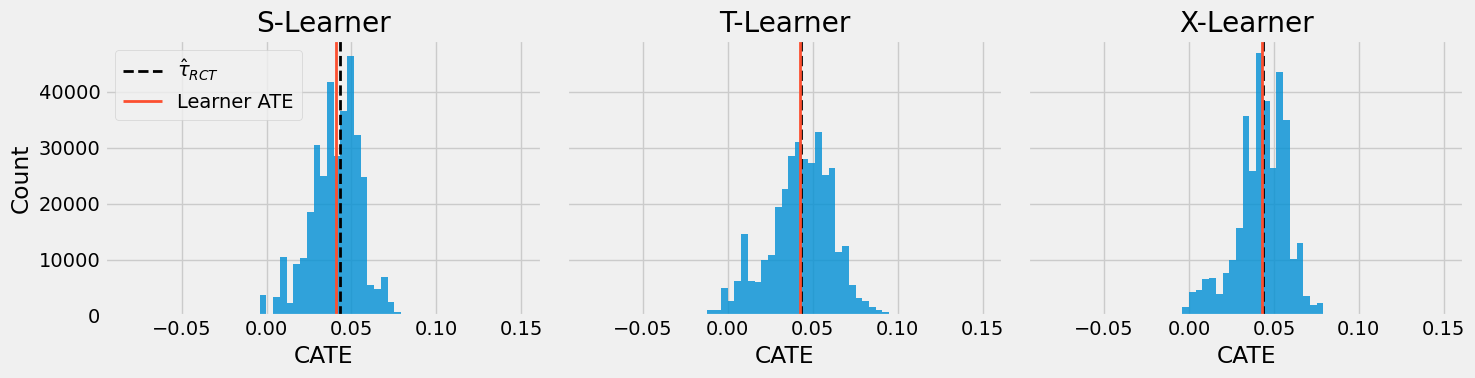

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
bins = np.linspace(df[names].min().min(), df[names].max().max(), 60)
for ax, n in zip(axes, names):
    ax.hist(df[n], bins=bins, alpha=.8)
    ax.axvline(tau_rct, color="black", ls="--", lw=2, label=r"$\hat\tau_{RCT}$")
    ax.axvline(df[n].mean(), color="C1", lw=2, label="Learner ATE")
    ax.set_title(n); ax.set_xlabel("CATE")
axes[0].set_ylabel("Count"); axes[0].legend()
plt.tight_layout(); plt.show()

In [17]:
# Agreement in levels and in rankings
print(df[names].corr(method="pearson").round(3))
print(df[names].corr(method="spearman").round(3))

# Agreement on the top 20% most responsive voters
top = {n: df[n] >= df[n].quantile(.8) for n in names}
for a, b in [("S-Learner","T-Learner"), ("S-Learner","X-Learner"), ("T-Learner","X-Learner")]:
    print(f"Top-20% overlap {a[0]}/{b[0]}: {(top[a] & top[b]).sum() / top[a].sum():.2%}")

# Which covariates drive heterogeneity? Mean CATE by past turnout
df["past_votes"] = df[["g2000", "g2002", "p2000", "p2002", "p2004"]].sum(axis=1)
print(df.groupby("past_votes")[names].mean().round(4))

# Validate against raw data: diff-in-means within each group
print(df.groupby("past_votes").apply(
    lambda g: g.loc[g[T]==1, y].mean() - g.loc[g[T]==0, y].mean()).round(4))

           S-Learner  T-Learner  X-Learner
S-Learner      1.000      0.826      0.862
T-Learner      0.826      1.000      0.868
X-Learner      0.862      0.868      1.000
           S-Learner  T-Learner  X-Learner
S-Learner      1.000      0.818      0.830
T-Learner      0.818      1.000      0.859
X-Learner      0.830      0.859      1.000
Top-20% overlap S/T: 68.12%
Top-20% overlap S/X: 61.52%
Top-20% overlap T/X: 70.33%
            S-Learner  T-Learner  X-Learner
past_votes                                 
0.0            0.0118     0.0121     0.0153
1.0            0.0299     0.0305     0.0311
2.0            0.0394     0.0382     0.0406
3.0            0.0479     0.0510     0.0473
4.0            0.0429     0.0489     0.0485
5.0            0.0311     0.0306     0.0466
past_votes
0.0    0.0090
1.0    0.0303
2.0    0.0390
3.0    0.0522
4.0    0.0490
5.0    0.0246
dtype: float64


C:\Users\jonat\AppData\Local\Temp\ipykernel_8456\2669579544.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df.groupby("past_votes").apply(
